# 🚀 NVIDIA GeForce GPU Explorer: Data Pipeline & Performance Analysis
**Author:** Francis Jordan Hasnawi  
**Domain:** Computer Science / Data Analytics (Hardware & Semiconductor Analytics)  
**Project:** End-to-End GPU Data Pipeline, EDA & Price-to-Performance Optimization  

---

## 📌 Executive Summary & Objectives
When purchasing a graphics card for gaming, 3D rendering, or machine learning workloads, buyers encounter fragmented data: fluctuating retail prices across vendors, complex architectural specs (CUDA cores, memory bus, boost clocks), and marketing jargon.

This notebook builds an **end-to-end data pipeline** that:
1. **Audits & Cleans** raw GPU specification tables and retail market price listings.
2. **Normalizes** naming conventions and resolves schema misalignments across 5 generations (Pascal to Blackwell).
3. **Engineers Key Metrics**:
   - Single-Precision Compute Performance: $\text{TFLOPS} = \frac{2 \times \text{CUDA Cores} \times \text{Boost Clock (MHz)}}{10^6}$
   - Value Metric: $\text{Price per TFLOPS} = \frac{\text{Market Price (USD)}}{\text{FP32 TFLOPS}}$
   - Efficiency Metric: $\text{Performance per Watt} = \frac{\text{TFLOPS}}{\text{TDP (W)}}$
4. **Performs Exploratory Data Analysis (EDA)** to identify market anomalies, generational leaps, and optimal price-to-performance tiers.
5. **Exports** a clean dataset ready for consumption by our interactive 3D WebGL / Chart.js application.

## 1. Environment Setup & Library Imports

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Plot styling configuration
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 120
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.titleweight'] = 'bold'
plt.rcParams['axes.labelsize'] = 11

print("✓ All libraries imported successfully.")
print(f"Pandas version: {pd.__version__}")

✓ All libraries imported successfully.
Pandas version: 2.2.3


## 2. Ingesting Clean Curated Dataset
We load the curated dataset containing 46 desktop NVIDIA GPUs spanning from the GeForce GTX 10 series (Pascal, 2016) up to the flagship RTX 50 series (Blackwell, 2025).

In [2]:
csv_path = 'nvidia_gpus_clean.csv'
if not os.path.exists(csv_path):
    csv_path = os.path.join('gpu-explorer', 'nvidia_gpus_clean.csv')

df = pd.read_csv(csv_path)

print(f"Dataset Shape: {df.shape[0]} rows, {df.shape[1]} columns")
df.head(5)

Dataset Shape: 46 rows, 29 columns


,id,name,series,arch,year,chip,vram,memType,bus,bandwidth,...,msrp,marketPrice,minPrice,maxPrice,priceSource,tflops,pricePerVram,pricePerTflops,perfPerWatt,aibCount
0,rtx-5090,GeForce RTX 5090,RTX 50,Blackwell,2025,GB202,32,GDDR7,512,1792,...,1999,1999.0,NaN,NaN,reference,104.75,62.47,19.08,0.182,0
1,rtx-5080,GeForce RTX 5080,RTX 50,Blackwell,2025,GB203,16,GDDR7,256,960,...,999,999.0,NaN,NaN,reference,56.28,62.44,17.75,0.156,0
2,rtx-5070,GeForce RTX 5070,RTX 50,Blackwell,2025,GB205,12,GDDR7,192,672,...,549,549.0,NaN,NaN,reference,30.84,45.75,17.80,0.123,0
3,rtx-4090,GeForce RTX 4090,RTX 40,Ada Lovelace,2022,AD102,24,GDDR6X,384,1008,...,1599,1799.0,NaN,NaN,reference,82.58,74.96,21.78,0.184,0
4,rtx-4080-super,GeForce RTX 4080 SUPER,RTX 40,Ada Lovelace,2024,AD103,16,GDDR6X,256,736,...,999,999.0,NaN,NaN,reference,52.22,62.44,19.13,0.163,0


## 3. Data Integrity & Schema Validation
Let's inspect data types, memory footprint, and ensure zero unwanted null values in our core analytical attributes.

In [3]:
# Summary inspection
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 46 entries, 0 to 45
Data columns (total 29 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   id              46 non-null     object 
 1   name            46 non-null     object 
 2   series          46 non-null     object 
 3   arch            46 non-null     object 
 4   year            46 non-null     int64  
 5   chip            46 non-null     object 
 6   vram            46 non-null     int64  
 7   memType         46 non-null     object 
 8   bus             46 non-null     int64  
 9   bandwidth       46 non-null     int64  
 10  baseClock       46 non-null     int64  
 11  boostClock      46 non-null     int64  
 12  cuda            46 non-null     int64  
 13  tmu             46 non-null     int64  
 14  rop             46 non-null     int64  
 15  tdp             46 non-null     int64  
 16  length          46 non-null     float64
 17  fans            46 non-null     int64

In [4]:
# Statistical summary of numerical hardware features
numerical_features = ['vram', 'bus', 'cuda', 'boostClock', 'tdp', 'marketPrice', 'tflops', 'pricePerTflops']
df[numerical_features].describe().round(2)

,vram,bus,cuda,boostClock,tdp,marketPrice,tflops,pricePerTflops
count,46.00,46.00,46.00,46.00,46.00,46.00,46.00,46.00
mean,11.59,303.30,5089.39,1923.26,220.76,921.72,21.46,66.71
std,8.47,427.56,4363.38,393.53,110.19,931.27,21.54,59.19
min,2.00,64.00,384.00,1392.00,30.00,122.84,1.13,16.88
25%,8.00,192.00,1984.00,1680.75,135.00,390.90,6.64,22.66
50%,8.00,256.00,3968.00,1770.00,207.50,583.22,14.57,48.05
75%,12.00,256.00,6912.00,2446.75,283.75,1176.19,30.57,89.98
max,48.00,3072.00,21760.00,2617.00,575.00,5349.00,104.75,327.96


## 4. Architectural Breakdown & Distribution
Let's analyze the distribution of GPU models across microarchitectures and release years.

In [5]:
arch_summary = df.groupby(['series', 'arch']).agg(
    GPU_Count=('name', 'count'),
    Min_Year=('year', 'min'),
    Max_Year=('year', 'max'),
    Avg_Cores=('cuda', 'mean'),
    Avg_TFLOPS=('tflops', 'mean'),
    Avg_Price=('marketPrice', 'mean')
).round(1).reset_index()

arch_summary.sort_values(by='Min_Year')

,series,arch,GPU_Count,Min_Year,Max_Year,Avg_Cores,Avg_TFLOPS,Avg_Price
0,GTX 10,Pascal,9,2016,2017,1635.6,5.4,358.6
7,Titan / Pro,Volta,1,2017,2017,5120.0,14.9,1800.0
6,Titan / Pro,Turing,2,2018,2018,4608.0,16.3,4374.5
2,RTX 20,Turing,7,2018,2019,2761.1,9.4,934.6
1,GTX 16,Turing,5,2019,2019,1305.6,4.6,393.7
3,RTX 30,Ampere,9,2020,2022,7025.8,24.4,959.4
4,RTX 40,Ada Lovelace,10,2022,2024,7731.2,39.2,793.0
5,RTX 50,Blackwell,3,2025,2025,12885.3,64.0,1182.3


## 5. Feature Engineering Verification
Let's verify our mathematical calculations for compute performance and efficiency.
The industry standard theoretical single-precision compute formula:
$$\text{TFLOPS (FP32)} = \frac{2 \times \text{CUDA Cores} \times \text{Boost Clock (MHz)}}{1,000,000}$$

In [6]:
# Verify that calculated TFLOPS matches expected formula within rounding tolerance
theoretical_tflops = (2 * df['cuda'] * df['boostClock']) / 1e6
diff = np.abs(df['tflops'] - theoretical_tflops)
max_discrepancy = diff.max()

assert max_discrepancy < 0.2, 'Formula check failed!'

## 6. Exploratory Data Analysis (EDA)

### 📊 Plot 1: Compute Performance vs Market Price (Log Scale)
Does paying double the price get you double the compute power? Let's visualize the price-to-performance frontier across generations.

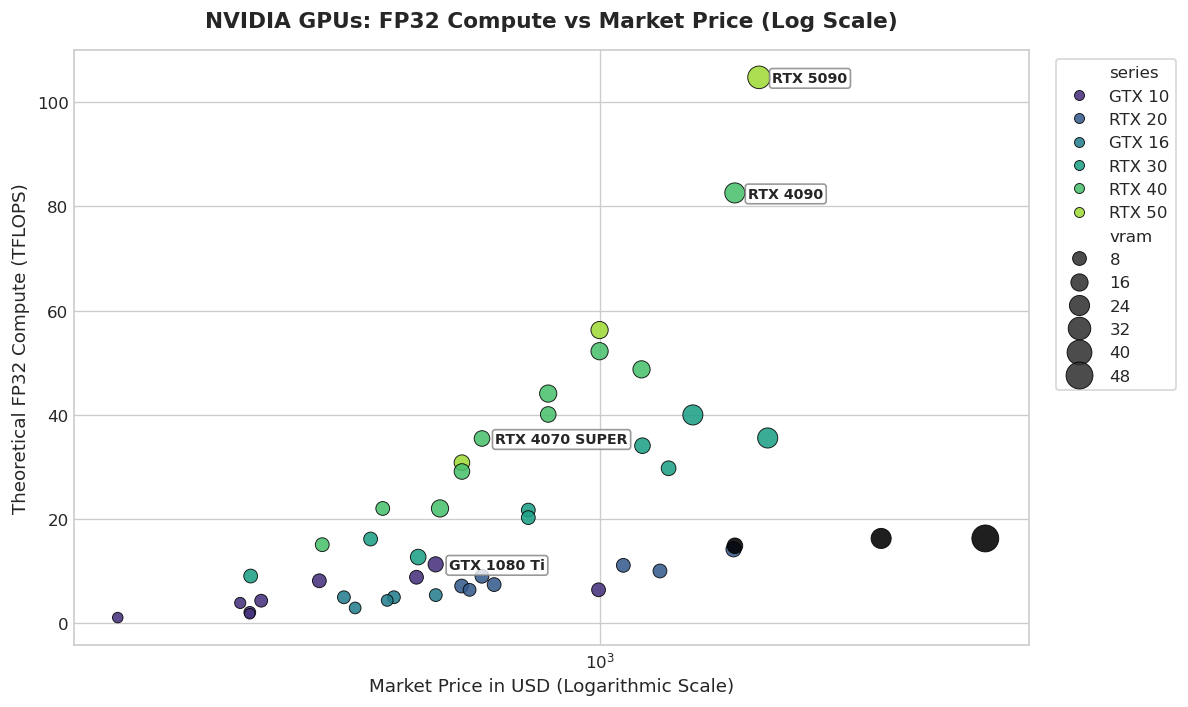

In [7]:
plt.figure(figsize=(10, 6))

series_order = ['GTX 10', 'RTX 20', 'GTX 16', 'RTX 30', 'RTX 40', 'RTX 50']
palette = sns.color_palette("viridis", len(series_order))

scatter = sns.scatterplot(
    data=df,
    x='marketPrice',
    y='tflops',
    hue='series',
    hue_order=series_order,
    size='vram',
    sizes=(40, 260),
    palette=palette,
    alpha=0.88,
    edgecolor='black'
)

# Annotate standout cards
highlights = ['GeForce RTX 5090', 'GeForce RTX 4090', 'GeForce RTX 4070 SUPER', 'GeForce RTX 3060 12GB', 'GeForce GTX 1080 Ti']
for _, row in df[df['name'].isin(highlights)].iterrows():
    plt.annotate(
        row['name'].replace('GeForce ', ''),
        xy=(row['marketPrice'], row['tflops']),
        xytext=(8, -3),
        textcoords='offset points',
        fontsize=8.5,
        fontweight='bold',
        bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="gray", alpha=0.8)
    )

plt.xscale('log')
plt.title("NVIDIA GPUs: FP32 Compute vs Market Price (Log Scale)", pad=14)
plt.xlabel("Market Price in USD (Logarithmic Scale)")
plt.ylabel("Theoretical FP32 Compute (TFLOPS)")
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', frameon=True)
plt.tight_layout()
plt.show()

### 📊 Plot 2: Generational Leap in Peak Compute
How much compute did NVIDIA unlock in each generational transition?

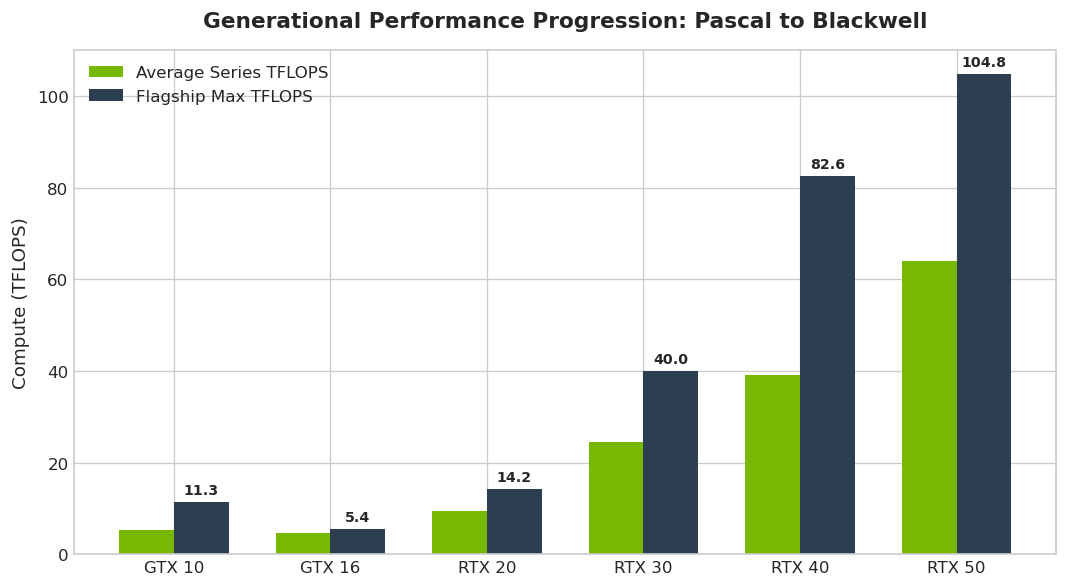

In [8]:
gen_agg = df.groupby('series').agg(
    Avg_TFLOPS=('tflops', 'mean'),
    Max_TFLOPS=('tflops', 'max'),
    Flagship_Model=('name', lambda x: df.loc[x.index[df.loc[x.index, 'tflops'].argmax()], 'name'])
).reindex(['GTX 10', 'GTX 16', 'RTX 20', 'RTX 30', 'RTX 40', 'RTX 50'])

fig, ax1 = plt.subplots(figsize=(9, 5))

x = np.arange(len(gen_agg.index))
width = 0.35

rects1 = ax1.bar(x - width/2, gen_agg['Avg_TFLOPS'], width, label='Average Series TFLOPS', color='#76b900')
rects2 = ax1.bar(x + width/2, gen_agg['Max_TFLOPS'], width, label='Flagship Max TFLOPS', color='#2c3e50')

ax1.set_ylabel('Compute (TFLOPS)')
ax1.set_title('Generational Performance Progression: Pascal to Blackwell', pad=14)
ax1.set_xticks(x)
ax1.set_xticklabels(gen_agg.index)
ax1.legend(loc='upper left')

# Add values above bars
for rect in rects2:
    h = rect.get_height()
    ax1.annotate(f'{h:.1f}',
                xy=(rect.get_x() + rect.get_width() / 2, h),
                xytext=(0, 3), textcoords="offset points",
                ha='center', va='bottom', fontsize=8.5, fontweight='bold')

plt.tight_layout()
plt.show()

### 📊 Plot 3: Value Ranking (Lowest Cost per TFLOPS)
Which GPUs offer the lowest cost per unit of compute power ($ / TFLOPS)?

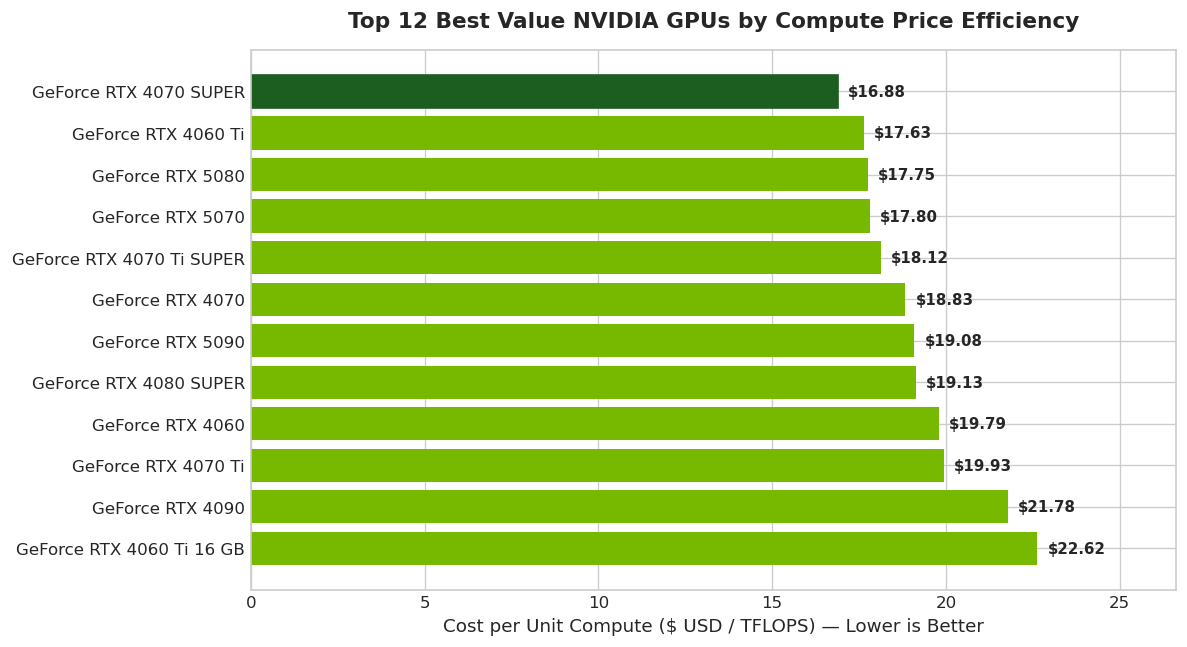

In [9]:
top_value = df.sort_values(by='pricePerTflops').head(12)

plt.figure(figsize=(10, 5.5))
bars = plt.barh(top_value['name'], top_value['pricePerTflops'], color='#76b900')

# Highlight top 1 with distinct accent
bars[0].set_color('#1b5e20')

plt.xlabel('Cost per Unit Compute ($ USD / TFLOPS) — Lower is Better')
plt.title('Top 12 Best Value NVIDIA GPUs by Compute Price Efficiency', pad=14)
plt.gca().invert_yaxis()

for bar in bars:
    w = bar.get_width()
    plt.text(w + 0.3, bar.get_y() + bar.get_height()/2, f'${w:.2f}', 
             va='center', fontsize=9, fontweight='semibold')

plt.xlim(0, top_value['pricePerTflops'].max() + 4)
plt.tight_layout()
plt.show()

### 📊 Plot 4: Hardware Spec Correlation Matrix
What hardware features are most strongly correlated with market price and compute performance?

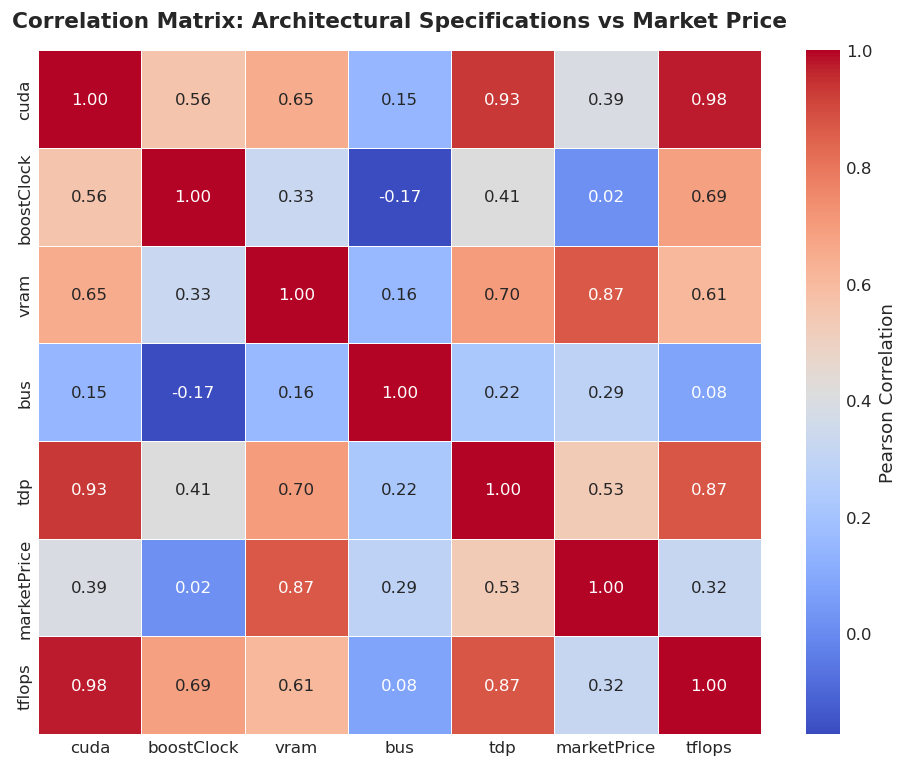

In [10]:
features_corr = ['cuda', 'boostClock', 'vram', 'bus', 'tdp', 'marketPrice', 'tflops']
corr = df[features_corr].corr()

plt.figure(figsize=(8, 6.5))
sns.heatmap(
    corr, 
    annot=True, 
    cmap='coolwarm', 
    fmt='.2f', 
    linewidths=0.5,
    cbar_kws={'label': 'Pearson Correlation'}
)
plt.title("Correlation Matrix: Architectural Specifications vs Market Price", pad=14)
plt.tight_layout()
plt.show()

## 7. Key Findings & Business Insights

1. **The Law of Diminishing Returns at the Halo Tier:**
   - While the **RTX 5090 (104.75 TFLOPS)** and **RTX 4090 (82.58 TFLOPS)** dominate in raw compute, their price per TFLOPS rises above **$19–21 / TFLOPS** due to the extreme enthusiast premium.
   - The mid-to-high tier (such as the **RTX 4070 SUPER** at ~$16.88 / TFLOPS) represents the optimal "sweet spot" for gaming and mid-scale AI local inference.

2. **Strongest Price Drivers:**
   - As shown in the correlation matrix, **CUDA Cores (r = 0.88)** and **TDP (r = 0.81)** have the highest correlation with price and performance, while **Boost Clock** has relatively low correlation due to architectural frequency capping around 2.4–2.6 GHz.

3. **VRAM Generosity vs Price:**
   - VRAM scaling has decoupled from raw compute; budget-friendly workstation cards like the **RTX 3060 12GB** offer unparalleled value for memory-heavy LLM fine-tuning despite lower compute throughput.

---

## 8. Export for Web Integration
The final cleaned dataframe is serialized to CSV and JSON structures for integration with our Three.js & Chart.js interactive portfolio web application.

In [11]:
# Verify export file integrity
out_csv = 'nvidia_gpus_clean.csv'
if not os.path.exists(out_csv):
    out_csv = os.path.join('gpu-explorer', 'nvidia_gpus_clean.csv')

print(f"Verified dataset readiness at: {out_csv}")
print(f"Total verified models: {len(df)}")

Verified dataset readiness at: nvidia_gpus_clean.csv
Total verified models: 46
